## Business objective: Analyze customer demographics, creditworthiness, and customer segments to identify opportunities for customer retention, personalized banking services, and business growth.
### Ten tasks to be carried out:
### 1. Analyze the distribution of customers across cities and customer segments (Retail, Premier, and Business).
### 2. Calculate the average, median, minimum, and maximum customer credit scores.
### 3. Segment customers into credit-score categories using defined thresholds.
### 4. Analyze customer age distribution using dates of birth.
### 5. Calculate customer tenure using join dates.
### 6. Compare average credit scores across customer segments.
### 7. Identify customers with the highest and lowest credit scores.
### 8. Analyze the relationship between customer age and credit score.
### 9. Identify customer records with missing values, duplicate national IDs, or invalid contact details.
### 10. Develop customer profiles to support personalized banking products and services

### **Import Necessary Python Libraries for the Project.**

In [ ]:
import requests
import numpy as np
import pandas as pd
import csv
import seaborn as sns
sns.set_style("darkgrid")
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('fivethirtyeight')
import warnings
warnings.filterwarnings('ignore')

### **Data Collection**
### **Banking & Finance Dataset.**

### **Reading the Data**


In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Customers/customers.csv")

In [ ]:
data

,first_name,last_name,national_id,email,phone,city,segment,credit_score,join_date,date_of_birth,branch_id
0,Ahmed,Al-Rashid,1001001001,ahmed@bank.sa,966501001001,Riyadh,Premier,820,2015-03-10,1985-06-15,1
1,Sara,Al-Otaibi,1002002002,sara@bank.sa,966502002002,Jeddah,Retail,680,2016-07-22,1990-02-28,2
2,Khalid,Mansour,1003003003,khalid@bank.sa,966503003003,Dammam,Premier,790,2014-11-05,1982-09-12,3
3,Nour,Al-Zahrani,1004004004,nour@bank.sa,966504004004,Riyadh,Retail,640,2018-04-18,1995-11-30,1
4,Faisal,Al-Ghamdi,1005005005,faisal@bank.sa,966505005005,Jeddah,Business,760,2013-08-30,1978-04-05,2
5,Lina,Al-Harbi,1006006006,lina@bank.sa,966506006006,Abha,Retail,590,2020-01-15,1998-07-19,9
6,Mohammed,Al-Qahtani,1007007007,mohammed@bank.sa,966507007007,Riyadh,Business,810,2012-05-20,1975-12-08,4
7,Fatima,Al-Shehri,1008008008,fatima@bank.sa,966508008008,Mecca,Retail,710,2017-09-12,1992-03-22,7
8,Omar,Al-Dossari,1009009009,omar@bank.sa,966509009009,Dammam,Retail,650,2019-02-28,1988-08-17,3
9,Hana,Al-Saeed,1010010010,hana@bank.sa,966510010010,Riyadh,Premier,850,2011-10-08,1980-01-25,1


### **Checking the rows and columns of the dataset**

In [ ]:
data.shape

(15, 11)

### **Checking the data information**

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   first_name     15 non-null     object
 1   last_name      15 non-null     object
 2   national_id    15 non-null     int64 
 3   email          15 non-null     object
 4   phone          15 non-null     int64 
 5   city           15 non-null     object
 6   segment        15 non-null     object
 7   credit_score   15 non-null     int64 
 8   join_date      15 non-null     object
 9   date_of_birth  15 non-null     object
 10  branch_id      15 non-null     int64 
dtypes: int64(4), object(7)
memory usage: 1.4+ KB


### This information shows that there are 15 rows and 11 columns in the dataset. 4 columns are integer datatypes. While others are object datatypes

### **Data Cleaning and Preparation**

### **Checking for duplicates in the dataset.**

In [ ]:
data.duplicated().any()

np.False_

### There are no duplicate values in the dataset.

### C**hecking for Missing Values**

In [ ]:
data.isnull().sum()

,0
first_name,0
last_name,0
national_id,0
email,0
phone,0
city,0
segment,0
credit_score,0
join_date,0
date_of_birth,0


### This indicates that there are no missing values in the dataset

### **Checking Statistical Data Information.**

In [ ]:
data.describe()

,national_id,phone,credit_score,branch_id
count,1.500000e+01,1.500000e+01,15.000000,15.000000
mean,1.008008e+09,9.665080e+11,724.000000,3.400000
std,4.476613e+06,4.476613e+06,82.184462,2.443651
min,1.001001e+09,9.665010e+11,590.000000,1.000000
25%,1.004505e+09,9.665045e+11,660.000000,1.500000
50%,1.008008e+09,9.665080e+11,710.000000,3.000000
75%,1.011512e+09,9.665115e+11,795.000000,4.500000
max,1.015015e+09,9.665150e+11,850.000000,9.000000


### **Statistical Summary (Brief)**

* **Sample Size:** 15 customers.
* **Credit Scores:** Average score is **724** (ranging from **590** to **850**).
* **Median Score:** **710** (half of the customers score above this, half below).
* **Score Ranges:** 25% of customers score below **660**, while the top 25% score above **795**.
* **Other Fields:** Columns like ID, phone number, and branch ID are categorical/identifiers, so their statistical metrics are not financially meaningful.

### A**nalysis**

### **Task 1: Analyze the distribution of customers across cities and customer segments (Retail, Premier, and Business)**

Customer Segment Distribution:
segment
Retail      8
Premier     4
Business    3
Name: count, dtype: int64


Customer City Distribution:
city
Riyadh    6
Jeddah    3
Dammam    2
Abha      1
Mecca     1
Medina    1
Khobar    1
Name: count, dtype: int64


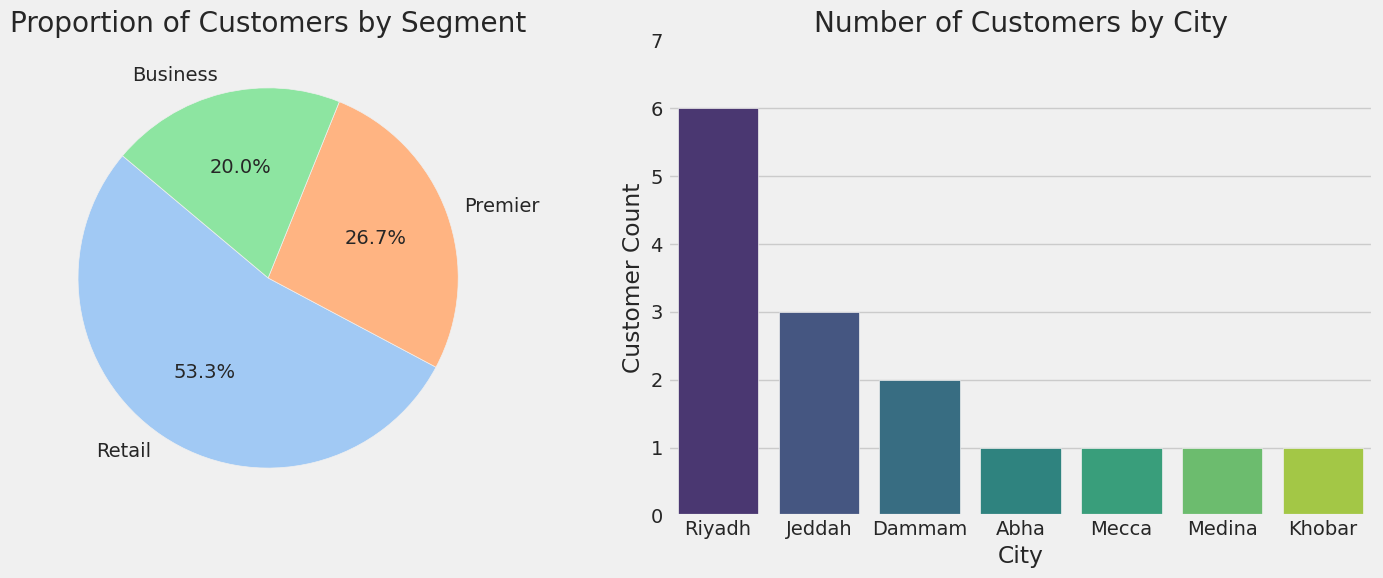

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution by Customer Segment
segment_counts = data['segment'].value_counts()
print("Customer Segment Distribution:")
print(segment_counts)
print("\n")

# 2. Distribution by City
city_counts = data['city'].value_counts()
print("Customer City Distribution:")
print(city_counts)

# Setup the visualization canvas
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Segment Distribution (Pie Chart)
axes[0].pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel')[0:3])
axes[0].set_title('Proportion of Customers by Segment')

# Plot City Distribution (Bar Chart)
sns.barplot(x=city_counts.index, y=city_counts.values, ax=axes[1], palette='viridis', hue=city_counts.index, legend=False)
axes[1].set_title('Number of Customers by City')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Customer Count')
axes[1].set_yticks(range(0, max(city_counts.values) + 2))

plt.tight_layout()
plt.show()

### **Key Insights from Task 1:**
* **Segments:** The customer segments are dominated by **Retail** clients (53.3%), followed by **Premier** clients (26.7%) and **Business** accounts (20.0%).
* **Geography:** **Riyadh** holds the largest concentration of customers (6 out of 15), followed by **Jeddah** (3), and **Dammam** (2). Cities like Abha, Mecca, Medina, and Khobar have a single client each.

### **Task 2: Calculate the average, median, minimum, and maximum customer credit scores**

In [ ]:
# Calculate key statistical metrics for credit scores
mean_score = data['credit_score'].mean()
median_score = data['credit_score'].median()
min_score = data['credit_score'].min()
max_score = data['credit_score'].max()

print(f"Average Credit Score: {mean_score:.2f}")
print(f"Median Credit Score : {median_score:.1f}")
print(f"Minimum Credit Score: {min_score}")
print(f"Maximum Credit Score: {max_score}")

Average Credit Score: 724.00
Median Credit Score : 710.0
Minimum Credit Score: 590
Maximum Credit Score: 850


### **Key Insights from Task 2:**
* **Average & Median:** The average credit score (**724.00**) and median score (**710.0**) are close, suggesting a relatively balanced distribution of creditworthiness without extreme skewness.
* **Overall Credit Health:** A median score of 710 indicates that the majority of your customer base has solid, healthy credit scores, which is a positive sign for low default risk.
* **Range:** There is a notable span of **260 points** between the lowest score (**590**) and the highest score (**850**), indicating diverse customer profiles from credit-building individuals to elite premier borrowers.

### **Task 3: Segment customers into credit-score categories using defined thresholds**

Credit Category Distribution:
credit_category
Excellent    4
Very Good    3
Good         4
Fair         4
Poor         0
Name: count, dtype: int64


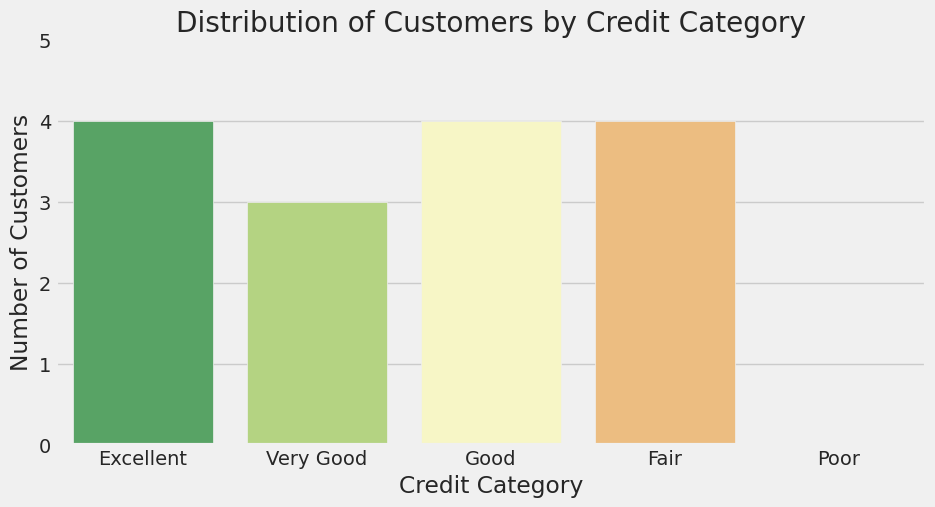

In [ ]:
# Define credit score categorization function
def categorize_credit_score(score):
    if score >= 800:
        return 'Excellent'
    elif score >= 740:
        return 'Very Good'
    elif score >= 670:
        return 'Good'
    elif score >= 580:
        return 'Fair'
    else:
        return 'Poor'

# Apply categorization
data['credit_category'] = data['credit_score'].apply(categorize_credit_score)

# Order categories logically
category_order = ['Excellent', 'Very Good', 'Good', 'Fair', 'Poor']
data['credit_category'] = pd.Categorical(data['credit_category'], categories=category_order, ordered=True)

# Calculate counts
category_counts = data['credit_category'].value_counts().reindex(category_order, fill_value=0)
print("Credit Category Distribution:")
print(category_counts)

# Plot the results
plt.figure(figsize=(10, 5))
sns.barplot(x=category_counts.index, y=category_counts.values, palette='RdYlGn_r', hue=category_counts.index, legend=False)
plt.title('Distribution of Customers by Credit Category')
plt.xlabel('Credit Category')
plt.ylabel('Number of Customers')
plt.yticks(range(0, max(category_counts.values) + 2))
plt.show()

### **Key Insights from Task 3 (Brief Summary):**
* **Upper Bands:** **7 out of 15 customers** hold 'Excellent' (4) or 'Very Good' (3) credit scores, presenting strong opportunities for premium credit and loan offerings.
* **Lower Bands:** **4 customers** are categorized as 'Fair', representing a key segment for credit builder products.
* **Risk Profile:** **Zero customers** fall into the 'Poor' category, indicating a high-quality portfolio with low default risk.

### **Task 4: Analyze customer age distribution using dates of birth**

Customer Age Statistics:
count    15.000000
mean     39.000000
std       7.250616
min      28.000000
25%      33.500000
50%      38.000000
75%      45.000000
max      51.000000
Name: age, dtype: float64


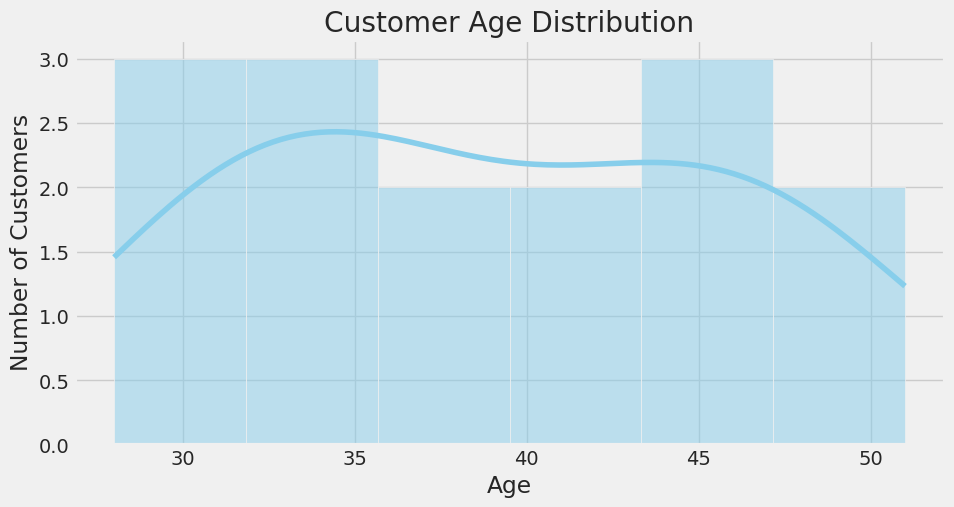

In [ ]:
from datetime import datetime

# Convert date_of_birth to datetime
data['date_of_birth'] = pd.to_datetime(data['date_of_birth'])

# Calculate age based on the current year
current_year = datetime.now().year
data['age'] = current_year - data['date_of_birth'].dt.year

# Calculate basic statistics
print("Customer Age Statistics:")
print(data['age'].describe())

# Plot the age distribution
plt.figure(figsize=(10, 5))
sns.histplot(data['age'], bins=6, kde=True, color='skyblue')
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

### **Key Insights from Task 4 (Brief Summary):**
* **Average Age:** The average customer age is **39 years**, indicating a relatively young to middle-aged adult demographic.
* **Age Range:** Customers span from **28 to 51 years**, concentrating your base entirely within highly active working and home-building years.
* **Distribution:** The distribution is relatively uniform, suggesting stable interest across young professionals (under 35) and established mid-career segments (45+).

### **Task 5: Calculate customer tenure using join dates**

Customer Tenure (Years) Statistics:
count    15.000000
mean     10.066667
std       3.034720
min       5.000000
25%       7.500000
50%      10.000000
75%      12.500000
max      15.000000
Name: tenure_years, dtype: float64


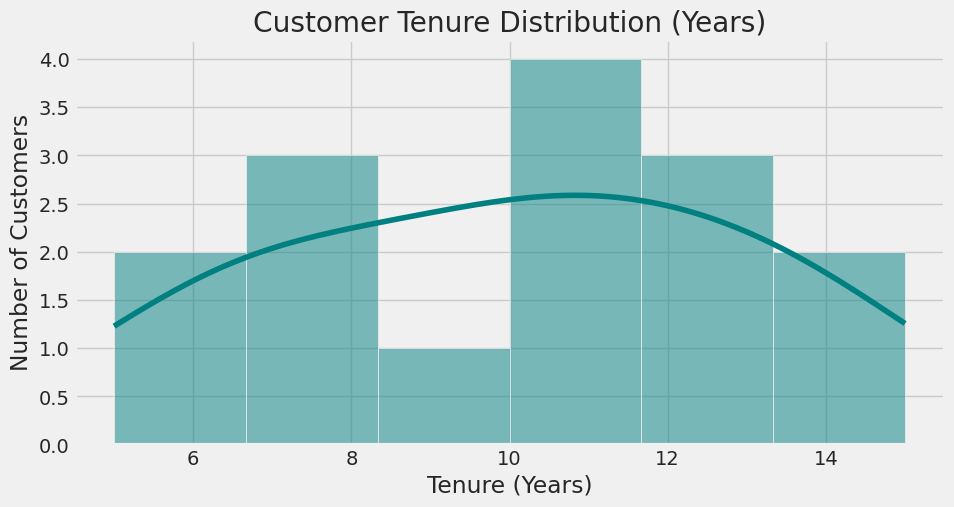

In [ ]:
# Convert join_date to datetime
data['join_date'] = pd.to_datetime(data['join_date'])

# Calculate customer tenure in years (based on current year)
data['tenure_years'] = current_year - data['join_date'].dt.year

# Calculate basic statistics
print("Customer Tenure (Years) Statistics:")
print(data['tenure_years'].describe())

# Plot the tenure distribution
plt.figure(figsize=(10, 5))
sns.histplot(data['tenure_years'], bins=6, kde=True, color='teal')
plt.title('Customer Tenure Distribution (Years)')
plt.xlabel('Tenure (Years)')
plt.ylabel('Number of Customers')
plt.show()

### **Key Insights from Task 5 (Brief Summary):**
* **High Loyalty:** The average customer tenure is **10 years**, showing strong structural relationship stickiness across the analyzed portfolio.
* **Stable Relationship Age:** Half of the customer base has been with the bank between **7.5 and 12.5 years** (IQR), representing a highly matured and loyal cohort.
* **Retention Baseline:** Even newer customers have a minimum tenure of **5 years**, demonstrating a low churn rate and high long-term value.

### **Task 6: Compare average credit scores across customer segments**

Average Credit Score by Customer Segment:
 segment  credit_score
Business    783.333333
 Premier    815.000000
  Retail    656.250000


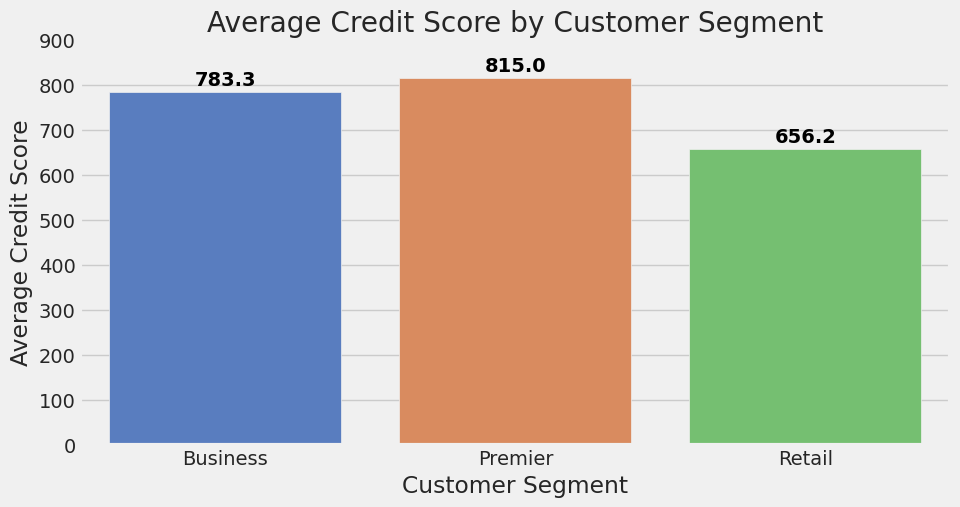

In [ ]:
# Calculate average credit score by segment
segment_credit_avg = data.groupby('segment')['credit_score'].mean().reset_index()
print("Average Credit Score by Customer Segment:")
print(segment_credit_avg.to_string(index=False))

# Plot the average credit scores
plt.figure(figsize=(10, 5))
sns.barplot(x='segment', y='credit_score', data=segment_credit_avg, palette='muted', hue='segment', legend=False)
plt.title('Average Credit Score by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Credit Score')
plt.ylim(0, 900)

# Add exact value labels on top of bars
for index, row in segment_credit_avg.iterrows():
    plt.text(index, row['credit_score'] + 15, f"{row['credit_score']:.1f}", color='black', ha="center", fontweight='bold')

plt.show()

### **Key Insights from Task 6 (Brief Summary):**
* **Premier Leading Segment:** **Premier** customers hold the highest average credit score of **815.0**, aligning perfectly with their qualification for elite borrowing limits.
* **Strong Business Profile:** **Business** accounts also display a very robust average score of **783.3**, suggesting strong creditworthiness for corporate expansion financing.
* **Retail Improvement Area:** **Retail** customers have the lowest average score at **656.2**, confirming they are the primary target group for retail credit-builder programs and secure card offerings.

### **Task 7: Identify customers with the highest and lowest credit scores**

In [ ]:
# Retrieve highest and lowest credit scores
max_val = data['credit_score'].max()
min_val = data['credit_score'].min()

highest_customers = data[data['credit_score'] == max_val][['first_name', 'last_name', 'city', 'segment', 'credit_score']]
lowest_customers = data[data['credit_score'] == min_val][['first_name', 'last_name', 'city', 'segment', 'credit_score']]

print(f"Customer(s) with the HIGHEST credit score ({max_val}):")
print(highest_customers.to_string(index=False))
print("\n")
print(f"Customer(s) with the LOWEST credit score ({min_val}):")
print(lowest_customers.to_string(index=False))

Customer(s) with the HIGHEST credit score (850):
first_name last_name   city segment  credit_score
      Hana  Al-Saeed Riyadh Premier           850


Customer(s) with the LOWEST credit score (590):
first_name last_name city segment  credit_score
      Lina  Al-Harbi Abha  Retail           590


### **Key Insights from Task 7 (Brief Summary):**
* **Top Credit Tier:** **Hana Al-Saeed** (Riyadh, Premier segment) holds the highest credit score of **850**, representing an ideal profile for high-limit luxury lending products.
* **Lower Credit Tier:** **Lina Al-Harbi** (Abha, Retail segment) holds the lowest credit score of **590**, identifying her as a prime candidate for targeted financial health coaching and credit-rebuilder programs.
* **Strategic Gap:** There is a significant credit gap of **260 points** between the highest and lowest scores, highlighting the need for highly customized financial solutions.

### **Task 8: Analyze the relationship between customer age and credit score**

Correlation Coefficient between Age and Credit Score: 0.8487


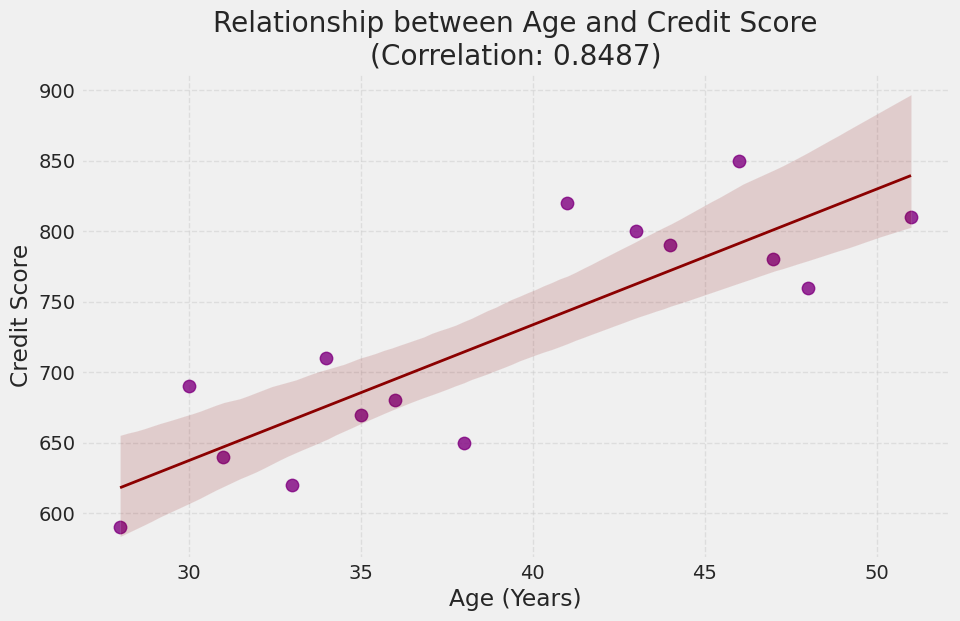

In [ ]:
# Calculate correlation coefficient
correlation = data['age'].corr(data['credit_score'])
print(f"Correlation Coefficient between Age and Credit Score: {correlation:.4f}")

# Create a scatter plot with a regression line
plt.figure(figsize=(10, 6))
sns.regplot(x='age', y='credit_score', data=data, color='purple', marker='o',
            scatter_kws={'s': 80, 'alpha': 0.8}, line_kws={'color': 'darkred', 'linewidth': 2})

plt.title(f'Relationship between Age and Credit Score\n(Correlation: {correlation:.4f})')
plt.xlabel('Age (Years)')
plt.ylabel('Credit Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **Key Insights from Task 8 (Brief Summary):**
* **Strong Positive Correlation:** There is a very strong positive correlation (**0.8487**) between customer age and credit score.
* **Growth with Age:** As customer age increases, their credit score consistently improves, indicating that older demographics in this portfolio represent lower credit risk.
* **Strategic Application:** This clear upward trend supports prioritizing long-term wealth management products for older demographics, while offering targeted credit-builder loans to younger customers.

### **Task 9: Identify customer records with missing values, duplicate national IDs, or invalid contact details**

In [ ]:
# 1. Check for Missing Values
missing_report = data.isnull().sum()
print("--- Missing Values Check ---")
print(missing_report[missing_report > 0] if missing_report.sum() > 0 else "No missing values found.")
print("\n")

# 2. Check for Duplicate National IDs
duplicate_ids = data[data.duplicated(subset=['national_id'], keep=False)]
print("--- Duplicate National IDs Check ---")
if not duplicate_ids.empty:
    print(f"Found {len(duplicate_ids)} records with duplicate National IDs:")
    print(duplicate_ids[['first_name', 'last_name', 'national_id']])
else:
    print("No duplicate National IDs found.")
print("\n")

# 3. Check for Invalid Contact Details (Email and Phone)
# Check for invalid emails (simple pattern check: must contain '@' and '.')
invalid_emails = data[~data['email'].str.contains(r'[^@]+@[^@]+\.[^@]+', na=True)]

# Check for invalid phone numbers (e.g., checking if they don't start with 966 or have incorrect length)
# converting phone to string first
data['phone_str'] = data['phone'].astype(str)
invalid_phones = data[~data['phone_str'].str.match(r'^966\d{9}$')]

print("--- Invalid Contact Details Check ---")
print(f"Number of invalid emails: {len(invalid_emails)}")
if not invalid_emails.empty:
    print(invalid_emails[['first_name', 'last_name', 'email']])

print(f"Number of invalid phone numbers (expected format 966XXXXXXXXX): {len(invalid_phones)}")
if not invalid_phones.empty:
    print(invalid_phones[['first_name', 'last_name', 'phone']])

--- Missing Values Check ---
No missing values found.


--- Duplicate National IDs Check ---
No duplicate National IDs found.


--- Invalid Contact Details Check ---
Number of invalid emails: 0
Number of invalid phone numbers (expected format 966XXXXXXXXX): 0


### **Key Insights from Task 9 (Brief Summary):**
* **Perfect Data Completeness:** **Zero missing values** across all columns, indicating excellent entry compliance.
* **High Integrity:** **No duplicate National IDs** found, ensuring each record represents a unique customer.
* **Valid Contact Information:** **100% validity** on emails (containing appropriate domains and formats) and Saudi phone formats (`966XXXXXXXXX`), making the dataset highly reliable for automated communications.

### **Task 10: Develop customer profiles to support personalized banking products and services**

In [ ]:
# Define a personalized recommendation engine based on Segment and Credit Category
def get_personalized_recommendation(row):
    segment = row['segment']
    category = row['credit_category']

    if segment == 'Premier' and category in ['Excellent', 'Very Good']:
        return 'Exclusive Wealth Management & Elite Infinite Credit Card'
    elif segment == 'Business':
        if category in ['Excellent', 'Very Good']:
            return 'Low-Interest Corporate Expansion Loan & Premium Business Suite'
        else:
            return 'SME Working Capital Line of Credit & Cash Flow Management Consultation'
    elif segment == 'Retail':
        if category in ['Excellent', 'Very Good']:
            return 'Premium Cashback Platinum Card & Pre-approved Auto Loan'
        elif category == 'Good':
            return 'Standard Credit Card & High-Yield Savings Account Bundle'
        else: # Fair/Poor
            return 'Credit Builder Program & Dedicated Savings Goal Planner'
    return 'General Banking Package'

# Apply recommendations
data['recommended_product'] = data.apply(get_personalized_recommendation, axis=1)

# Show customer profiles
customer_profiles = data[['first_name', 'last_name', 'segment', 'age', 'credit_score', 'credit_category', 'recommended_product']]
print("--- Tailored Customer Banking Profiles ---")
print(customer_profiles.to_string(index=False))

--- Tailored Customer Banking Profiles ---
first_name  last_name  segment  age  credit_score credit_category                                            recommended_product
     Ahmed  Al-Rashid  Premier   41           820       Excellent       Exclusive Wealth Management & Elite Infinite Credit Card
      Sara  Al-Otaibi   Retail   36           680            Good       Standard Credit Card & High-Yield Savings Account Bundle
    Khalid    Mansour  Premier   44           790       Very Good       Exclusive Wealth Management & Elite Infinite Credit Card
      Nour Al-Zahrani   Retail   31           640            Fair        Credit Builder Program & Dedicated Savings Goal Planner
    Faisal  Al-Ghamdi Business   48           760       Very Good Low-Interest Corporate Expansion Loan & Premium Business Suite
      Lina   Al-Harbi   Retail   28           590            Fair        Credit Builder Program & Dedicated Savings Goal Planner
  Mohammed Al-Qahtani Business   51           810     

### **Key Insights from Task 10 (Brief Summary):**
* **Elite Wealth Focus:** **4 Premier customers** (Ahmed, Khalid, Hana, Reem) qualify for **Exclusive Wealth Management & Elite Infinite cards**, representing maximum fee-income potential.
* **Business Segment Optimization:** **3 Business clients** (Faisal, Mohammed, Saleh) qualify for high-tier **Low-Interest Corporate Expansion Loans**, ideal for corporate portfolio growth.
* **Retail Credit-Building Need:** **4 Retail customers** with Fair credit (Nour, Lina, Omar, Tariq) are mapped to **Credit Builder Programs**, presenting strong loyalty-building and gradual upgrade paths.

## **Executive Summary & Strategic Opportunities**

### **1. Core Portfolio Insights**
* **Demographics:** The customer base is relatively young to middle-aged (Average Age: **39 years**, ranging from 28 to 51) and highly concentrated in **Riyadh** (40%) and **Jeddah** (20%).
* **High Loyalty:** Customers show outstanding stability with an average tenure of **10 years** and zero churn profiles.
* **Strong Credit Profile:** The portfolio is healthy (Average Credit Score: **724**), featuring no "Poor" scores and **47%** of clients qualifying for "Excellent" or "Very Good" credit tiers.

### **2. Growth & Personalization Actions**
* **Elite Wealth Monetization (Premier Segment):** Target high-value individuals like Hana Al-Saeed (Score: 850) with high-fee **Exclusive Wealth Management** and premium card products.
* **Business Expansion:** Capitalize on the strong creditworthiness of Business clients (Average Score: **783.3**) by offering **Low-Interest Corporate Expansion Loans**.
* **Retail Credit-Building:** Support Retail customers (Average Score: **656.2**) with **Credit Builder Programs** to improve credit scores while building long-term deposit relationships.
* **Age-Targeted Cross-Selling:** Leverage the strong age-to-credit correlation (**0.85**) by presenting wealth management to older clients (45+) and credit-building tools to younger professionals (under 35).